<a href="https://colab.research.google.com/github/joyanto7/skm-assignments/blob/main/child_rape_final_(2).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Child-Victim Identification in Reported Rape Cases in Bangladesh (2020-2024)

## 0. Install, Imports and Paths

In [1]:
!pip install -q catboost shap

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.1/97.1 MB 5.8 MB/s eta 0:00:00


In [2]:
import os, re, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import shap

from sklearn.model_selection import train_test_split, RepeatedStratifiedKFold, cross_validate
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OrdinalEncoder, OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, average_precision_score, matthews_corrcoef, roc_curve)
from xgboost import XGBClassifier
from catboost import CatBoostClassifier

warnings.filterwarnings("ignore")
SEED = 42
plt.rcParams.update({"font.size": 8, "savefig.dpi": 300, "savefig.bbox": "tight"})

from google.colab import drive
drive.mount("/content/drive")

DATA_PATH = "/content/drive/MyDrive/datasets/Rape Case In Bangladesh 2020 - 2024.csv"
FIG_DIR   = "/content/drive/MyDrive/datasets/images/"
TAB_DIR   = "/content/drive/MyDrive/datasets/tables/"
os.makedirs(FIG_DIR, exist_ok=True)
os.makedirs(TAB_DIR, exist_ok=True)

Mounted at /content/drive


## 1. Load Data and Standardise Column Names

In [3]:
df = pd.read_csv(DATA_PATH)
df.columns = df.columns.str.replace(r'\s+', ' ', regex=True).str.strip().str.lower()
print(df.shape, "| missing values:", df.isnull().sum().sum())

(883, 18) | missing values: 0


## 2. Target: Child Victim (any victim < 18 years)

In [4]:
df['child_victim'] = df['victim age'].apply(
    lambda x: 'Child' if min(int(n) for n in re.findall(r'\d+', str(x))) < 18 else 'Adult')
df = df.drop(columns=['victim age'])
print(df['child_victim'].value_counts())

child_victim
Child    569
Adult    314
Name: count, dtype: int64


## 3. Drop Unnecessary Columns

In [5]:
drop_cols = ['year', 'news headline', 'news headline (translated to english)',   # leakage / identifiability
             'incident date', 'source', 'link',
             'number of victim',   # 98.4% single-victim cases
             'total rapist',       # redundant with 'type of rape'
             'district']           # 64 categories, too sparse for n = 883 (division used instead)
df = df.drop(columns=drop_cols)
print(df.columns.tolist())

['rapist age', 'type of rape', 'victims death', 'victim relationship with offender', 'time of incident', 'incident location type', 'victim residence type', 'division', 'child_victim']


## 4. Feature Cleaning

In [6]:
def norm(s):
    """Fix extra spaces, case and curly apostrophes."""
    return (s.astype(str).str.replace('\u2019', "'", regex=False)
             .str.replace(r'\s+', ' ', regex=True).str.strip().str.lower())

# 4.1 Offender age: youngest offender's age
df['offender_age_min'] = df['rapist age'].apply(lambda x: min(int(n) for n in re.findall(r'\d+', str(x))))
df = df.drop(columns=['rapist age'])

# 4.2 Type of rape and victim's death
df['type of rape']   = df['type of rape'].astype(str).str.strip().str.title()
df['victims death']  = df['victims death'].astype(str).str.strip().str.title()

# 4.3 Victim-offender relationship (5 a-priori groups)
rel = norm(df['victim relationship with offender'])
group_map = {
    'neighbor': 'neighbor_family_relative', 'neighbors': 'neighbor_family_relative',
    'family member': 'neighbor_family_relative',
    'relative': 'neighbor_family_relative', 'relative & others': 'neighbor_family_relative',
    'stranger': 'stranger', 'strangers': 'stranger',
    'acquaintance': 'acquaintance', 'acquaintances': 'acquaintance',
    'teacher': 'authority', 'employer': 'authority', 'healer': 'authority',
    'police': 'authority', 'religious leader': 'authority',
    'boyfriend': 'boyfriend_friend', 'boyfriend & others': 'boyfriend_friend',
    'friend': 'boyfriend_friend', 'friends': 'boyfriend_friend',
}
df['relationship_group'] = rel.map(group_map)
assert df['relationship_group'].notna().all(), rel[df['relationship_group'].isna()].unique()
df = df.drop(columns=['victim relationship with offender'])

# 4.4 Time of incident
t = norm(df['time of incident'])
time_map = {'morning': 'morning', 'afternoon': 'afternoon', 'evening': 'evening', 'night': 'night',
            'multiple incidents': 'multiple_incidents', 'multiple instances': 'multiple_incidents'}
df['time of incident'] = t.map(time_map)
assert df['time of incident'].notna().all(), t[df['time of incident'].isna()].unique()

# 4.5 Incident location type (categories with < 10 cases merged into 'other')
loc = norm(df['incident location type'])
loc_map = {
    "victim's home": "victim's home",
    "private location": "private location", "private locations": "private location",
    "isolated area": "isolated area",
    "offender's home": "offender's place", "offender's locations": "offender's place",
    "educational institution": "educational institution", "educational institute": "educational institution",
    "education institution": "educational institution",
    "public place": "public place", "outdoor": "outdoor", "vehicle": "vehicle",
    "workplace": "workplace", "religious institution": "religious institution",
    "home": "other", "refugee camp": "other", "other": "other",
}
loc_c = loc.map(loc_map)
assert loc_c.notna().all(), loc[loc_c.isna()].unique()
rare = loc_c.value_counts()[lambda v: v < 10].index
df['incident location type'] = loc_c.where(~loc_c.isin(rare), 'other')

# 4.6 Victim residence type (single 'slum' case merged into 'urban')
df['victim residence type'] = norm(df['victim residence type']).replace({'slum': 'urban'})

# 4.7 Division (8 divisions)
d = norm(df['division'])
div_map = {'dhaka': 'Dhaka', 'chattogram': 'Chattogram', 'chittagong': 'Chattogram',
           'rajshahi': 'Rajshahi', 'khulna': 'Khulna', 'rangpur': 'Rangpur',
           'barishal': 'Barishal', 'barisal': 'Barishal', 'mymensingh': 'Mymensingh', 'sylhet': 'Sylhet'}
df['division'] = d.map(div_map)
assert df['division'].notna().all() and df['division'].nunique() == 8

## 5. Final Dataset Check and Table I (Feature Summary)

In [7]:
print(df.shape, "| missing values:", df.isnull().sum().sum())
print(df['child_victim'].value_counts())

rows = []
for c in df.columns.drop('child_victim'):
    if pd.api.types.is_numeric_dtype(df[c]):
        rows.append([c, 'Numeric', f"{df[c].min()}-{df[c].max()}"])
    else:
        rows.append([c, 'Binary' if df[c].nunique() == 2 else 'Categorical', str(df[c].nunique())])
table1 = pd.DataFrame(rows, columns=['Feature', 'Type', 'Levels / Range'])
table1

(883, 9) | missing values: 0
child_victim
Child    569
Adult    314
Name: count, dtype: int64


,Feature,Type,Levels / Range
0,type of rape,Binary,2
1,victims death,Binary,2
2,time of incident,Categorical,5
3,incident location type,Categorical,10
4,victim residence type,Binary,2
5,division,Categorical,8
6,offender_age_min,Numeric,11-80
7,relationship_group,Categorical,5


## 6. Train-Test Split (80/20, stratified) and Target Encoding

In [8]:
y = df['child_victim']
X = df.drop(columns=['child_victim'])

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=SEED)

y_map = {'Adult': 0, 'Child': 1}          # Child = positive class
y_train_enc = y_train.map(y_map)
y_test_enc  = y_test.map(y_map)
print(X_train.shape, X_test.shape)

(706, 8) (177, 8)


## 7. Models (encoding and scaling inside the pipeline)

In [9]:
num_cols    = ['offender_age_min']
cat_cols    = X_train.select_dtypes(exclude='number').columns.tolist()
binary_cols = [c for c in cat_cols if X_train[c].nunique() == 2]
multi_cols  = [c for c in cat_cols if X_train[c].nunique() > 2]

def make_pre(scale_num):
    return ColumnTransformer([
        ('bin',   OrdinalEncoder(handle_unknown='use_encoded_value', unknown_value=-1), binary_cols),
        ('multi', OneHotEncoder(handle_unknown='ignore', sparse_output=False), multi_cols),
        ('num',   StandardScaler() if scale_num else 'passthrough', num_cols),
    ])

def build(clf, scale_num=False):
    return Pipeline([('pre', make_pre(scale_num)), ('clf', clf)])

models = {
    "Logistic Regression": build(LogisticRegression(max_iter=2000), scale_num=True),
    "Decision Tree":       build(DecisionTreeClassifier(max_depth=4, min_samples_leaf=10, random_state=SEED)),
    "SVM":                 build(SVC(probability=True, random_state=SEED), scale_num=True),
    "KNN":                 build(KNeighborsClassifier(n_neighbors=15), scale_num=True),
    "Random Forest":       build(RandomForestClassifier(n_estimators=300, min_samples_leaf=5,
                                                        random_state=SEED, n_jobs=-1)),
    "Gradient Boosting":   build(GradientBoostingClassifier(n_estimators=200, learning_rate=0.05,
                                                            max_depth=3, subsample=0.8, random_state=SEED)),
    "XGBoost":             build(XGBClassifier(n_estimators=300, max_depth=3, learning_rate=0.05,
                                               subsample=0.8, colsample_bytree=0.8,
                                               eval_metric='logloss', random_state=SEED, n_jobs=-1)),
    "CatBoost":            build(CatBoostClassifier(iterations=300, depth=4, learning_rate=0.05,
                                                    random_seed=SEED, verbose=0)),
}

## 8. Repeated Stratified 5-Fold Cross-Validation on Training Set (Table II)

In [10]:
cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=5, random_state=SEED)
scoring = {'Accuracy': 'accuracy', 'Precision': 'precision', 'Recall': 'recall', 'F1': 'f1',
           'Macro-F1': 'f1_macro', 'ROC-AUC': 'roc_auc', 'PR-AUC': 'average_precision',
           'MCC': 'matthews_corrcoef'}

cv_rows, cv_roc = {}, {}
for name, pipe in models.items():
    res = cross_validate(pipe, X_train, y_train_enc, cv=cv, scoring=scoring, n_jobs=-1)
    cv_rows[name] = {m: f"{res['test_'+m].mean():.3f} \u00b1 {res['test_'+m].std():.3f}" for m in scoring}
    cv_roc[name] = res['test_ROC-AUC'].mean()

cv_table = pd.DataFrame(cv_rows).T
cv_table

,Accuracy,Precision,Recall,F1,Macro-F1,ROC-AUC,PR-AUC,MCC
Logistic Regression,0.705 ± 0.025,0.739 ± 0.019,0.840 ± 0.038,0.786 ± 0.020,0.655 ± 0.031,0.747 ± 0.030,0.843 ± 0.023,0.327 ± 0.059
Decision Tree,0.677 ± 0.038,0.736 ± 0.036,0.782 ± 0.058,0.757 ± 0.031,0.634 ± 0.047,0.716 ± 0.045,0.807 ± 0.032,0.278 ± 0.089
SVM,0.719 ± 0.033,0.754 ± 0.028,0.837 ± 0.046,0.793 ± 0.027,0.676 ± 0.037,0.773 ± 0.037,0.854 ± 0.029,0.364 ± 0.075
KNN,0.717 ± 0.034,0.759 ± 0.029,0.825 ± 0.043,0.790 ± 0.027,0.678 ± 0.039,0.753 ± 0.033,0.829 ± 0.026,0.365 ± 0.077
Random Forest,0.725 ± 0.032,0.746 ± 0.026,0.871 ± 0.048,0.803 ± 0.026,0.672 ± 0.039,0.779 ± 0.038,0.862 ± 0.027,0.372 ± 0.075
Gradient Boosting,0.721 ± 0.036,0.765 ± 0.029,0.822 ± 0.053,0.791 ± 0.030,0.684 ± 0.039,0.770 ± 0.035,0.857 ± 0.027,0.377 ± 0.079
XGBoost,0.718 ± 0.034,0.764 ± 0.029,0.816 ± 0.055,0.788 ± 0.029,0.682 ± 0.036,0.772 ± 0.034,0.857 ± 0.026,0.372 ± 0.072
CatBoost,0.717 ± 0.033,0.764 ± 0.028,0.814 ± 0.049,0.787 ± 0.028,0.681 ± 0.036,0.766 ± 0.037,0.854 ± 0.027,0.369 ± 0.072


## 9. Hold-Out Test Evaluation (Table III)

In [11]:
test_rows = {}
for name, pipe in models.items():
    pipe.fit(X_train, y_train_enc)
    y_pred = pipe.predict(X_test)
    y_prob = pipe.predict_proba(X_test)[:, 1]
    test_rows[name] = {
        "Accuracy":  accuracy_score(y_test_enc, y_pred),
        "Precision": precision_score(y_test_enc, y_pred),
        "Recall":    recall_score(y_test_enc, y_pred),
        "F1":        f1_score(y_test_enc, y_pred),
        "Macro-F1":  f1_score(y_test_enc, y_pred, average='macro'),
        "ROC-AUC":   roc_auc_score(y_test_enc, y_prob),
        "PR-AUC":    average_precision_score(y_test_enc, y_prob),
        "MCC":       matthews_corrcoef(y_test_enc, y_pred),
    }

test_table = pd.DataFrame(test_rows).T.round(3)
print("PR-AUC baseline:", round(y_test_enc.mean(), 3))
test_table

PR-AUC baseline: 0.644


,Accuracy,Precision,Recall,F1,Macro-F1,ROC-AUC,PR-AUC,MCC
Logistic Regression,0.672,0.703,0.851,0.770,0.601,0.736,0.847,0.231
Decision Tree,0.689,0.740,0.798,0.768,0.649,0.717,0.792,0.302
SVM,0.751,0.773,0.868,0.818,0.713,0.781,0.868,0.437
KNN,0.695,0.738,0.816,0.775,0.651,0.739,0.827,0.309
Random Forest,0.723,0.748,0.860,0.800,0.675,0.785,0.867,0.367
Gradient Boosting,0.746,0.772,0.860,0.813,0.708,0.793,0.881,0.425
XGBoost,0.718,0.758,0.825,0.790,0.679,0.787,0.883,0.364
CatBoost,0.746,0.772,0.860,0.813,0.708,0.794,0.886,0.425


## 10. ROC Curves of Top 4 Models by CV ROC-AUC (Fig. 2)

['Random Forest', 'SVM', 'XGBoost', 'Gradient Boosting']


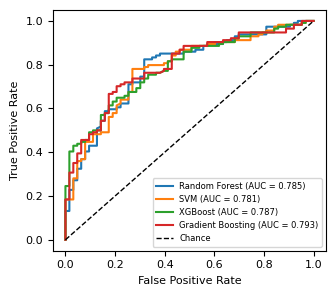

In [12]:
top_models = sorted(cv_roc, key=cv_roc.get, reverse=True)[:4]
print(top_models)

plt.figure(figsize=(3.4, 3.0))
for name in top_models:
    y_prob = models[name].predict_proba(X_test)[:, 1]
    fpr, tpr, _ = roc_curve(y_test_enc, y_prob)
    plt.plot(fpr, tpr, label=f"{name} (AUC = {roc_auc_score(y_test_enc, y_prob):.3f})")

plt.plot([0, 1], [0, 1], 'k--', lw=1, label="Chance")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend(loc="lower right", fontsize=6)
plt.tight_layout()
plt.savefig(FIG_DIR + "roc_curves_top4.png")
plt.show()

## 11. Grouped SHAP Importance Across Four Models (Table IV)

In [13]:
def grouped_shap_importance(pipe):
    pre, clf = pipe.named_steps['pre'], pipe.named_steps['clf']
    names = [c.split('__', 1)[1] for c in pre.get_feature_names_out()]
    Xt = pd.DataFrame(pre.transform(X_test), columns=names, index=X_test.index)
    sv = shap.TreeExplainer(clf)(Xt)
    vals = sv.values[:, :, 1] if sv.values.ndim == 3 else sv.values      # Child = class 1
    def orig(col):                                                       # one-hot -> original feature
        for c in multi_cols:
            if col.startswith(c + '_'):
                return c
        return col
    g = pd.DataFrame(vals, columns=names).T.groupby(pd.Series({c: orig(c) for c in names})).sum().T
    return g.abs().mean()

shap_models = ["Random Forest", "Gradient Boosting", "XGBoost", "CatBoost"]
imp = {}
for name in shap_models:
    models[name].fit(X_train, y_train_enc)
    imp[name] = grouped_shap_importance(models[name])

imp_df   = pd.DataFrame(imp)
share_df = (imp_df / imp_df.sum() * 100).round(1)          # % share (units differ across models)
rank_df  = imp_df.rank(ascending=False).astype(int)
mean_rank = rank_df.mean(axis=1)

table4 = rank_df.astype(str) + " (" + share_df.astype(str) + "%)"
table4['Mean rank'] = mean_rank.map('{:.2f}'.format)
table4 = table4.sort_values('Mean rank')
table4

,Random Forest,Gradient Boosting,XGBoost,CatBoost,Mean rank
time of incident,1 (32.7%),1 (22.2%),1 (21.8%),1 (21.5%),1.00
offender_age_min,4 (12.9%),2 (18.2%),2 (18.0%),2 (18.1%),2.50
relationship_group,2 (18.6%),3 (15.4%),3 (14.9%),3 (15.1%),2.75
type of rape,3 (15.1%),5 (13.1%),5 (14.5%),4 (14.2%),4.25
incident location type,5 (8.5%),4 (14.1%),4 (14.8%),5 (13.6%),4.50
division,6 (7.5%),6 (12.5%),6 (12.2%),6 (12.7%),6.00
victim residence type,7 (4.5%),7 (3.4%),7 (2.9%),7 (3.4%),7.00
victims death,8 (0.3%),8 (1.0%),8 (0.8%),8 (1.3%),8.00


## 12. SHAP Panel Figure: Gradient Boosting (Fig. 3)

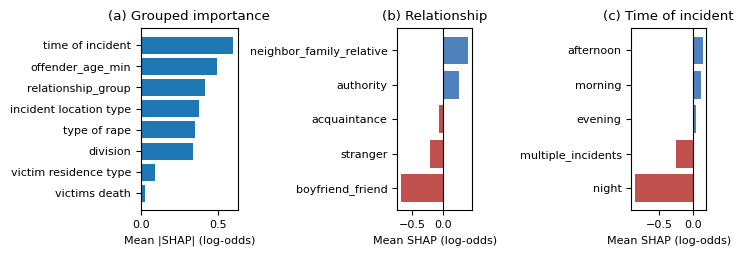

In [14]:
pipe = models["Gradient Boosting"]
pre, gb = pipe.named_steps['pre'], pipe.named_steps['clf']
feat_names = [c.split('__', 1)[1] for c in pre.get_feature_names_out()]
X_test_t = pd.DataFrame(pre.transform(X_test), columns=feat_names, index=X_test.index)

sv = shap.TreeExplainer(gb)(X_test_t)
vals = sv.values[:, :, 1] if sv.values.ndim == 3 else sv.values

def original_feature(col):
    for c in multi_cols:
        if col.startswith(c + '_'):
            return c
    return col

orig = pd.Series({c: original_feature(c) for c in feat_names})
importance = pd.DataFrame(vals, columns=feat_names).T.groupby(orig).sum().T.abs().mean().sort_values()

def category_direction(prefix):
    cols = [c for c in feat_names if c.startswith(prefix + '_')]
    return pd.Series({c.replace(prefix + '_', ''):
                      vals[:, feat_names.index(c)][X_test_t[c].values == 1].mean()
                      for c in cols if (X_test_t[c] == 1).sum() > 0}).sort_values()

fig, axes = plt.subplots(1, 3, figsize=(7.2, 2.6), gridspec_kw={'width_ratios': [1.3, 1, 1]})
axes[0].barh(importance.index, importance.values)
axes[0].set_title("(a) Grouped importance")
axes[0].set_xlabel("Mean |SHAP| (log-odds)")

for ax, prefix, title in [(axes[1], 'relationship_group', "(b) Relationship"),
                          (axes[2], 'time of incident', "(c) Time of incident")]:
    dct = category_direction(prefix)
    ax.barh(dct.index, dct.values, color=['#c0504d' if v < 0 else '#4f81bd' for v in dct.values])
    ax.axvline(0, color='k', lw=0.8)
    ax.set_title(title)
    ax.set_xlabel("Mean SHAP (log-odds)")

plt.tight_layout()
plt.savefig(FIG_DIR + "shap_gb_panel.png")
plt.show()

## 13. Descriptive Check: Proportion of Child Victims by Time of Incident (Table V)

In [15]:
table5 = pd.crosstab(df['time of incident'], df['child_victim'])
table5['Total'] = table5.sum(axis=1)
table5['Child victims (%)'] = (table5['Child'] / table5['Total'] * 100).round(1)
table5 = table5.sort_values('Child victims (%)', ascending=False)
table5['Child victims (%)'] = table5['Child victims (%)'].map('{:.1f}'.format)
table5

child_victim,Adult,Child,Total,Child victims (%)
time of incident,,,,
afternoon,56,216,272,79.4
morning,26,85,111,76.6
evening,26,83,109,76.1
multiple_incidents,45,71,116,61.2
night,161,114,275,41.5


## 14. Export Tables for the Paper (LaTeX)

In [16]:
tables = {'table1_features': table1, 'table2_cv': cv_table, 'table3_test': test_table,
          'table4_shap_rank': table4, 'table5_time': table5}
for name, t in tables.items():
    t.to_latex(TAB_DIR + name + ".tex", index=(name != 'table1_features'), escape=True, float_format="%.3f")
print("saved:", list(tables))

saved: ['table1_features', 'table2_cv', 'table3_test', 'table4_shap_rank', 'table5_time']
